# 33 — Research Synthesis & Supervisor Report
## Next-day hotspot prediction → GeoMAE-inspired contextual anomaly identification → spatial/wind refinement

**Purpose:** consolidate executed experimental artifacts into a transparent, audit-ready supervisor report. **No model training, no new test optimization, no redefinition of outcomes.**

### Four supervisor requests covered
1. Reduce questionable anomaly candidates by checking persistent historical hotspot sources (distance-first; wind as supporting context).
2. Evaluate whether vegetation information can be used; record Dynamic World coverage gate and limitations.
3. Test GeoMAE-inspired next-day forecasting against LR13 / NodeGRU-L14, including spatial/wind ablation.
4. Show a coherent chronology: **forecast t→t+1 first; after t+1 is observed, evaluate unusual hotspots and contextual priority.**

### Crucial distinction
The forecasting branch (NB24 → NB30/31/31B) and the final anomaly branch (NB24C → NB25–29D) are **related GeoMAE-inspired methods, but not the same trained encoder/checkpoint**. The final anomaly model uses a **temporal, fire-only masked-reconstruction model**, whereas the forecasting experiments use a **7-day × 3×3 spatiotemporal encoder**. Do not claim a jointly trained multi-task model.

### Scope / careful wording
- FIRMS VIIRS hotspot ≠ verified wildfire ignition or cause. Nearby source ≠ demonstrated fire spread.
- The refinement does **not** measure confirmed false-positive reduction (no independent verified-anomaly labels).
- August has been used in development; the summaries are **post-development descriptive**, not an independent final test.
- September was used by NB21 and re-examined in NB30/NB31; later comparisons are **post-test exploratory**.
- GeoMAE-ST is **proposed/investigated architecture**, not a proven universally best forecaster.

In [2]:
# 1. Imports & figure defaults
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch, FancyArrowPatch
from matplotlib.lines import Line2D
from sklearn.metrics import average_precision_score, precision_recall_curve
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
plt.rcParams.update({'axes.titlesize': 12, 'axes.labelsize': 10, 'figure.dpi': 110})
print('NB33 is analysis-only: no neural training and no model selection.')

NB33 is analysis-only: no neural training and no model selection.


In [3]:
# 2. Find project root and input exports
CANDIDATE_ROOTS = [Path.cwd(), Path.cwd().parent, Path('/content/skripsi-karhut'),
                   Path('/content/drive/MyDrive/skripsi-karhut')]
# Windows users: optionally set the exact root if working outside notebooks/.
PROJECT_ROOT_OVERRIDE = None  # e.g. Path(r'C:\Users\Asus\Documents\skripsi-karhut')

REQUIRED_RELATIVE = {
    'regional': 'data/processed/regional_025/karhut_ml_dataset_regional_025.csv',
    'refined': 'model_results/persistent_source_spatial_wind_refinement/t2/exports/august_emerging_distance_first_persistent_source_refined.csv',
    'sensitivity': 'model_results/persistent_source_spatial_wind_refinement/t2/exports/distance_first_persistent_source_refinement_sensitivity.csv',
    'august_prediction': 'model_results/geomae_controlled_ablation/t2/exports/all_model_august_predictions.csv',
}
OPTIONAL_RELATIVE = {
    'anomaly_candidates': 'model_results/final_masked_temporal_anomaly/t2/exports/august_final_robust_anomaly_candidates.csv',
    'nb29d_summary': 'model_results/persistent_source_spatial_wind_refinement/t2/exports/distance_first_persistent_source_refinement_summary.csv',
    'nb32_leaderboard': 'model_results/geomae_nb32_diagnostics/t2/exports/nb32_matched_leaderboard.csv',
    'nb32_ci': 'model_results/geomae_nb32_diagnostics/t2/exports/nb32_paired_dateblock_bootstrap.csv',
    'nb32_topk': 'model_results/geomae_nb32_diagnostics/t2/exports/nb32_topk_operational_comparison.csv',
    'nb32_cases': 'model_results/geomae_nb32_diagnostics/t2/exports/nb32_complementary_case_examples.csv',
    'nb32_positive_ranking': 'model_results/geomae_nb32_diagnostics/t2/exports/nb32_emerging_positive_ranking_all.csv',
    'nb32_wind': 'model_results/geomae_nb32_diagnostics/t2/exports/nb32_wind_context_diagnostics.csv',
    'dynamic_world_gate': 'model_results/dynamic_world_window_sensitivity/t2/exports/dynamic_world_window_decision.csv',
    'september_baselines': 'model_results/regional_025_final_test/t2/exports/final_september_predictions.csv',
    'september_geo_finetuned': 'model_results/geomae_st_wind_finetuned/t2/exports/september_three_model_predictions.csv',
}
root_pool = [Path(PROJECT_ROOT_OVERRIDE)] if PROJECT_ROOT_OVERRIDE else CANDIDATE_ROOTS
PROJECT_ROOT = next((p for p in root_pool if all((p/rel).exists() for rel in REQUIRED_RELATIVE.values())), None)
if PROJECT_ROOT is None:
    print('Missing source paths. Check NB29D and NB31B export cells before NB33.')
    for root in root_pool:
        print('Candidate:', root)
        for key, rel in REQUIRED_RELATIVE.items():
            print('  ', 'OK' if (root/rel).exists() else 'MISSING', key, rel)
    raise FileNotFoundError('Required NB33 inputs unavailable. This notebook never inserts invented data.')
PATHS = {k: PROJECT_ROOT/rel for k, rel in {**REQUIRED_RELATIVE, **OPTIONAL_RELATIVE}.items()}
OUT = PROJECT_ROOT/'model_results'/'research_synthesis_supervisor'/'t2'
FIG = OUT/'figures'
EX = OUT/'exports'
for p in (FIG, EX): p.mkdir(parents=True, exist_ok=True)
input_audit = pd.DataFrame([{'Source': k, 'Available': p.exists(), 'Path': str(p)} for k,p in PATHS.items()])
display(input_audit)
print('PROJECT_ROOT:', PROJECT_ROOT)
print('OUTPUT:', OUT)

,Source,Available,Path
0,regional,True,c:\Users\Asus\Documents\skripsi-karhut\data\pr...
1,refined,True,c:\Users\Asus\Documents\skripsi-karhut\model_r...
2,sensitivity,True,c:\Users\Asus\Documents\skripsi-karhut\model_r...
3,august_prediction,True,c:\Users\Asus\Documents\skripsi-karhut\model_r...
4,anomaly_candidates,True,c:\Users\Asus\Documents\skripsi-karhut\model_r...
5,nb29d_summary,True,c:\Users\Asus\Documents\skripsi-karhut\model_r...
6,nb32_leaderboard,True,c:\Users\Asus\Documents\skripsi-karhut\model_r...
7,nb32_ci,True,c:\Users\Asus\Documents\skripsi-karhut\model_r...
8,nb32_topk,True,c:\Users\Asus\Documents\skripsi-karhut\model_r...
9,nb32_cases,True,c:\Users\Asus\Documents\skripsi-karhut\model_r...


PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
OUTPUT: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2


In [4]:
# 3. Load source data & validate the row keys
regional = pd.read_csv(PATHS['regional'], parse_dates=['date'])
refined = pd.read_csv(PATHS['refined'], parse_dates=['date'])
sensitivity = pd.read_csv(PATHS['sensitivity'])
aug = pd.read_csv(PATHS['august_prediction'], parse_dates=['date'])
assert not regional.duplicated(['date','cell_id']).any(), 'Duplicate regional cell-day'
assert not refined.duplicated(['date','cell_id']).any(), 'Duplicate refined candidate'
assert not aug.duplicated(['date','cell_id']).any(), 'Duplicate August forecast origin'
assert aug['date'].between('2026-08-01','2026-08-31').all(), 'August forecast origins must be August only'
assert refined['date'].between('2026-08-01','2026-08-31').all(), 'Refinement dates must be August only'
assert aug['target_fire_active_t1'].dropna().isin([0,1]).all()
assert refined['refined_high_priority'].notna().all()

MODEL_COLS = {
  'LR13 baseline': 'LR13 baseline (matched train)',
  'NodeGRU-L14 baseline': 'nodegru_score',
  'GeoMAE-T': 'GeoMAE-T',
  'GeoMAE-ST': 'GeoMAE-ST',
  'GeoMAE-ST-Wind': 'GeoMAE-ST-Wind',
  'Transformer-ST-Wind Scratch': 'Transformer-ST-Wind Scratch',
}
required = set(MODEL_COLS.values()) | {'date','cell_id','target_fire_active_t1','active_days_prev3_incl_t'}
missing = sorted(required-set(aug.columns))
if missing: raise KeyError(f'Missing NB31B prediction columns: {missing}')
for col in MODEL_COLS.values():
    if not np.isfinite(pd.to_numeric(aug[col], errors='coerce')).all():
        raise ValueError(f'Non-finite score for {col}')
aug['y'] = aug['target_fire_active_t1'].astype(int)
aug['emerging_eligible'] = aug['active_days_prev3_incl_t'].eq(0)
assert len(aug) == 4123, f'Unexpected August row count: {len(aug)}'
assert regional['cell_id'].nunique() == 133
print(f'Regional records: {len(regional):,}; nodes: {regional.cell_id.nunique()}')
print(f'August forecasting: {len(aug):,} rows; Emerging-eligible: {aug.emerging_eligible.sum():,}; positives: {aug.loc[aug.emerging_eligible,"y"].sum():,}')
print(f'Refined Emerging candidates: {len(refined):,}')

Regional records: 16,625; nodes: 133
August forecasting: 4,123 rows; Emerging-eligible: 1,241; positives: 224
Refined Emerging candidates: 118


# PART I — Timeline and methodological story

**End of day t:** use hotspot/meteorological history available through t to forecast satellite hotspot presence at t+1. The predicted score is a **ranking**, not automatically a calibrated probability.

**After t+1 observations arrive:** identify hotspot-positive cells with unusual past patterns using the separately trained **fire-only temporal masked-reconstruction anomaly model**; then refine their investigation priority by historical persistent hotspot proximity and supportive wind alignment.

Thus, anomaly priority is assigned to an **observed hotspot** after its detection; it is *not* a prescient anomaly forecast at t. This temporal distinction avoids implying unknown t+1 fire observations were included in the t+1 forecast.

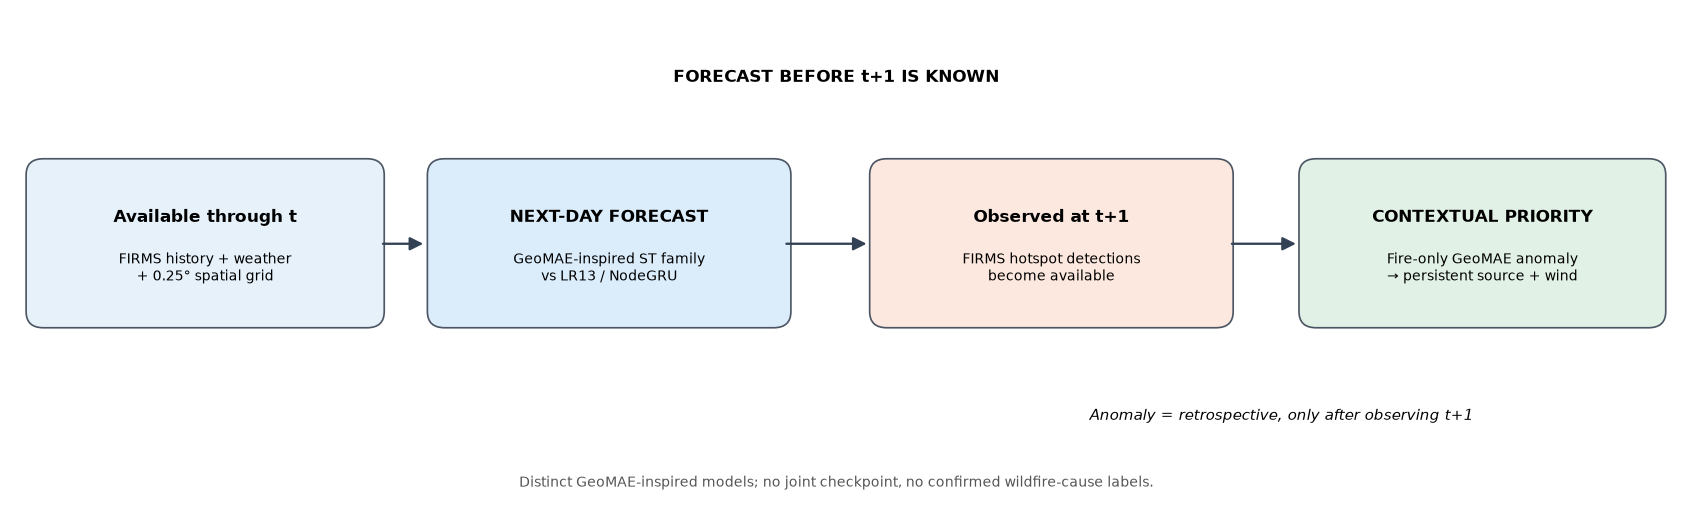

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2\figures\01_prediction_to_anomaly_workflow.png


In [5]:
# 4. Create a publication-style workflow diagram
fig, ax = plt.subplots(figsize=(15.5, 4.9))
ax.set_xlim(0, 15.5); ax.set_ylim(0, 5); ax.axis('off')
blocks = [
 (0.30, 2.03, 3.0, 1.35, 'Available through t', 'FIRMS history + weather\n+ 0.25° spatial grid', '#E6F1FA'),
 (4.02, 2.03, 3.05, 1.35, 'NEXT-DAY FORECAST', 'GeoMAE-inspired ST family\nvs LR13 / NodeGRU', '#DBECFA'),
 (8.12, 2.03, 3.05, 1.35, 'Observed at t+1', 'FIRMS hotspot detections\nbecome available', '#FCE8DE'),
 (12.10, 2.03, 3.08, 1.35, 'CONTEXTUAL PRIORITY', 'Fire-only GeoMAE anomaly\n→ persistent source + wind', '#E2F1E6'),
]
for x,y,w,h,title,sub,color in blocks:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.16',edgecolor='#4B5563',linewidth=1.1,facecolor=color))
    ax.text(x+w/2,y+0.93,title,ha='center',va='center',fontsize=11,fontweight='bold')
    ax.text(x+w/2,y+0.43,sub,ha='center',va='center',fontsize=9)
for a,b in [(3.42,3.85),(7.16,7.96),(11.29,11.94)]:
    ax.add_patch(FancyArrowPatch((a,2.7),(b,2.7),arrowstyle='-|>',mutation_scale=18,lw=1.5,color='#334155'))
ax.text(7.65,4.30,'FORECAST BEFORE t+1 IS KNOWN',ha='center',fontweight='bold',fontsize=11)
ax.text(11.78,0.96,'Anomaly = retrospective, only after observing t+1',ha='center',fontsize=10,style='italic')
ax.text(7.65,0.30,'Distinct GeoMAE-inspired models; no joint checkpoint, no confirmed wildfire-cause labels.',ha='center',fontsize=9,color='#555')
fig.tight_layout()
workflow_fig = FIG/'01_prediction_to_anomaly_workflow.png'
fig.savefig(workflow_fig,dpi=220,bbox_inches='tight')
plt.show()
print('Saved:',workflow_fig)

# PART II — Anomaly candidate refinement (NB25 → NB29D)

Robust anomaly candidates were defined using **actual hotspot-positive cells** and a masked-reconstruction ranking criterion across five seeds; this is a *candidate rule*, not externally validated ground truth. The NB29D refinement considers only **Emerging-3** robust candidates. Source persistence means hotspot-positive in **at least 2 of the three prior days**; a candidate within **40 km** of any such source is marked *spatially explainable/deprioritized*. Wind alignment is supportive only and does **not** control the main distance-first decision.

In [6]:
# 5. Recompute anomaly candidate counts from source exports
near = refined['deprioritized_near_persistent'].astype(bool)
isolated = refined['refined_high_priority'].astype(bool)
wind_supportive = refined['wind_supportive_near_source'].astype(bool)
assert (near & isolated).sum() == 0
assert (near | isolated).all()

counts = {
    'Emerging robust candidates': len(refined),
    'Near historical persistent source': int(near.sum()),
    '...near with supportive wind evidence': int((near & wind_supportive).sum()),
    '...near based on distance only': int((near & ~wind_supportive).sum()),
    'Isolated / higher-priority candidates': int(isolated.sum()),
}
# Fetch all robust anomalies from NB25 if present; otherwise from NB29D summary.
robust_total = None
if PATHS['anomaly_candidates'].exists():
    anomaly_all = pd.read_csv(PATHS['anomaly_candidates'])
    robust_total = len(anomaly_all)
elif PATHS['nb29d_summary'].exists():
    tmp = pd.read_csv(PATHS['nb29d_summary'])
    row = tmp[tmp['stage'].eq('All GeoMAE robust anomalies')]
    if len(row): robust_total = int(row.iloc[0]['count'])
if robust_total is not None: counts = {'All robust hotspot anomalies': robust_total, **counts}

anomaly_counts = pd.DataFrame([{'Stage': k, 'Count': v} for k,v in counts.items()])
display(anomaly_counts)
assert counts['Emerging robust candidates'] == counts['Near historical persistent source'] + counts['Isolated / higher-priority candidates']
print('ATTENTION: these are candidate prioritization counts, NOT confirmed false-positive reduction.')

,Stage,Count
0,All robust hotspot anomalies,620
1,Emerging robust candidates,118
2,Near historical persistent source,96
3,...near with supportive wind evidence,55
4,...near based on distance only,41
5,Isolated / higher-priority candidates,22


ATTENTION: these are candidate prioritization counts, NOT confirmed false-positive reduction.


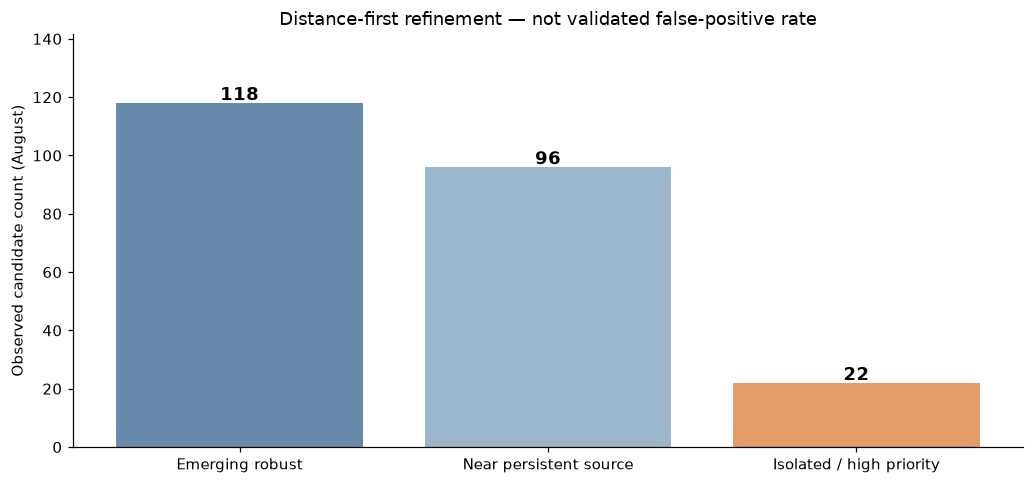

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2\figures\02_anomaly_refinement_counts.png


In [7]:
# 6. Visualize Emerging anomaly refinement, counts only
fig, ax = plt.subplots(figsize=(9.5,4.5))
labels=['Emerging robust','Near persistent source','Isolated / high priority']
vals=[len(refined),int(near.sum()),int(isolated.sum())]
bars=ax.bar(labels,vals,color=['#678AAA','#9CB7CB','#E59C68'])
for bar,val in zip(bars,vals): ax.text(bar.get_x()+bar.get_width()/2,val+1,str(val),ha='center',fontsize=12,fontweight='bold')
ax.set_ylim(0,max(vals)*1.20);ax.set_ylabel('Observed candidate count (August)')
ax.set_title('Distance-first refinement — not validated false-positive rate')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
p=FIG/'02_anomaly_refinement_counts.png';fig.savefig(p,dpi=210,bbox_inches='tight');plt.show();print('Saved:',p)

,min_active_days_prev3,near_radius_km,near_persistent_source,isolated_from_persistent_source,near_plus_wind_support
0,2,30.0,81,37,37
1,2,40.0,96,22,55
2,2,50.0,96,22,55
3,3,30.0,40,78,16
4,3,40.0,55,63,32
5,3,50.0,55,63,32


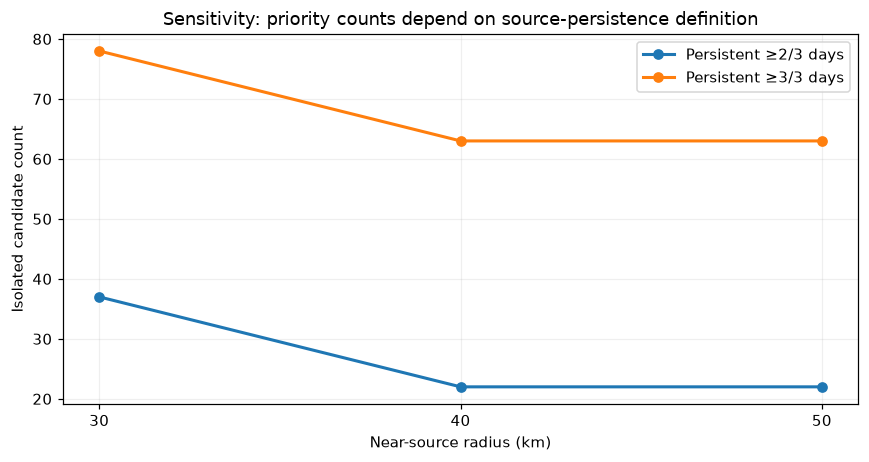

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2\figures\03_persistent_source_sensitivity.png


In [8]:
# 7. Sensitivity (2/3 vs 3/3 persistence; 30/40/50 km)
required_sens = {'min_active_days_prev3','near_radius_km','alignment_threshold','isolated_from_persistent_source'}
assert required_sens.issubset(sensitivity.columns)
ss=sensitivity[np.isclose(sensitivity['alignment_threshold'],0.5)].sort_values(['min_active_days_prev3','near_radius_km']).copy()
display(ss[['min_active_days_prev3','near_radius_km','near_persistent_source','isolated_from_persistent_source','near_plus_wind_support']].reset_index(drop=True))
fig,ax=plt.subplots(figsize=(8,4.3))
for min_days,g in ss.groupby('min_active_days_prev3'):
    ax.plot(g['near_radius_km'],g['isolated_from_persistent_source'],marker='o',linewidth=2,label=f'Persistent ≥{min_days}/3 days')
ax.set_xlabel('Near-source radius (km)');ax.set_ylabel('Isolated candidate count');ax.set_xticks([30,40,50]);ax.grid(alpha=.20);ax.legend()
ax.set_title('Sensitivity: priority counts depend on source-persistence definition')
fig.tight_layout()
p=FIG/'03_persistent_source_sensitivity.png';fig.savefig(p,dpi=200,bbox_inches='tight');plt.show();print('Saved:',p)

# PART III — Forecasting comparison: August development, same cell-day labels

**Emerging-3 eligible** means the target cell had no detected hotspot on t, t−1, and t−2 (derived from observations available by t); the target itself is hotspot presence on t+1. **Higher PR-AUC is better**, but this is not untouched testing: August was repeatedly used for development. Both the main benchmark and ablations are displayed, including results against GeoMAE-ST-Wind.

In [9]:
# 8. Matched PR-AUC, re-evaluated from NB31B exported scores
rows=[]
for name, col in MODEL_COLS.items():
    for label, subset in [('Overall',aug),('Emerging-3 eligible',aug[aug.emerging_eligible]),('Persistent-context',aug[~aug.emerging_eligible])]:
        if subset['y'].sum()==0: pr=np.nan
        else: pr=float(average_precision_score(subset['y'],subset[col]))
        rows.append({'Model':name,'Context':label,'Rows':len(subset),'Positives':int(subset.y.sum()),'PR-AUC':pr})
aug_results=pd.DataFrame(rows)
aug_pivot=aug_results.pivot(index='Model',columns='Context',values='PR-AUC')
aug_pivot['delta vs NodeGRU (Emerging)']=aug_pivot['Emerging-3 eligible']-aug_pivot.loc['NodeGRU-L14 baseline','Emerging-3 eligible']
display(aug_pivot.sort_values('Emerging-3 eligible',ascending=False).round(4))
assert aug_results.query('Context == "Emerging-3 eligible"')['Rows'].nunique() == 1

Context,Emerging-3 eligible,Overall,Persistent-context,delta vs NodeGRU (Emerging)
Model,,,,
NodeGRU-L14 baseline,0.3372,0.8665,0.8935,0.0000
GeoMAE-ST,0.3220,0.8225,0.9062,-0.0152
GeoMAE-T,0.2886,0.8364,0.9083,-0.0487
GeoMAE-ST-Wind,0.2855,0.7667,0.8928,-0.0517
LR13 baseline,0.2770,0.8776,0.9092,-0.0603
Transformer-ST-Wind Scratch,0.2529,0.8234,0.9067,-0.0844


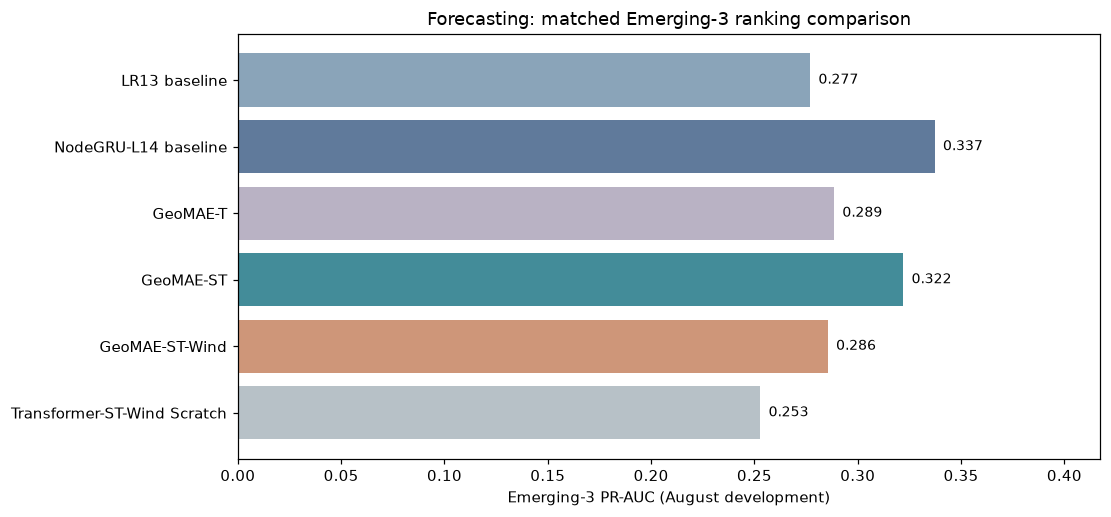

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2\figures\04_august_emerging_model_comparison.png


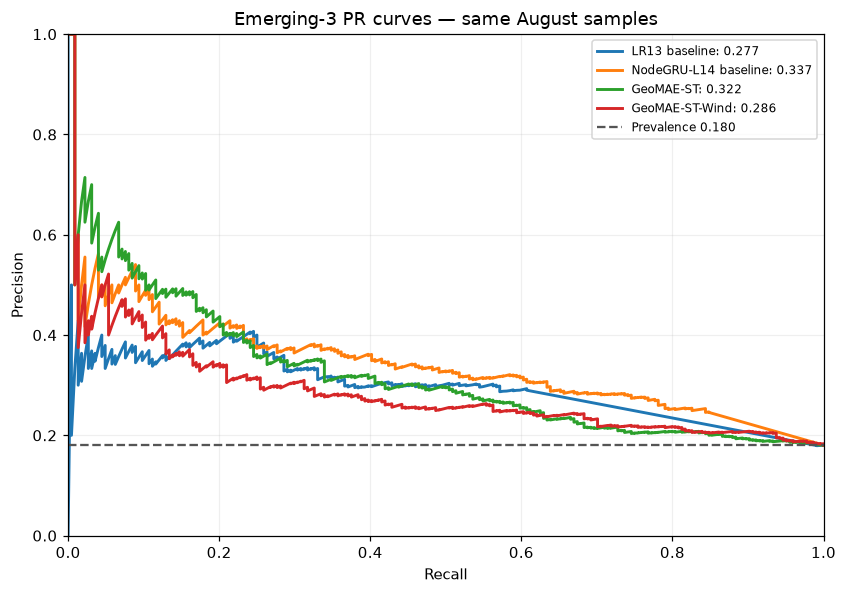

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2\figures\05_august_emerging_pr_curves.png


In [10]:
# 9. Emergence PR-AUC comparison plot and PR curves
em=aug[aug.emerging_eligible].copy()
plot_order=['LR13 baseline','NodeGRU-L14 baseline','GeoMAE-T','GeoMAE-ST','GeoMAE-ST-Wind','Transformer-ST-Wind Scratch']
values=[aug_pivot.loc[n,'Emerging-3 eligible'] for n in plot_order]
fig,ax=plt.subplots(figsize=(10.2,4.8))
bars=ax.barh(plot_order,values,color=['#8AA4B9','#607A9B','#B9B2C4','#438C99','#CE9679','#B7C1C7'])
for bar,val in zip(bars,values): ax.text(val+.004,bar.get_y()+bar.get_height()/2,f'{val:.3f}',va='center',fontsize=9)
ax.set_xlim(0,max(values)+.080);ax.invert_yaxis();ax.set_xlabel('Emerging-3 PR-AUC (August development)');ax.set_title('Forecasting: matched Emerging-3 ranking comparison')
fig.tight_layout();p=FIG/'04_august_emerging_model_comparison.png';fig.savefig(p,dpi=220,bbox_inches='tight');plt.show();print('Saved:',p)
fig,ax=plt.subplots(figsize=(7.8,5.5))
for name in ['LR13 baseline','NodeGRU-L14 baseline','GeoMAE-ST','GeoMAE-ST-Wind']:
    precision,recall,_=precision_recall_curve(em['y'],em[MODEL_COLS[name]])
    ax.plot(recall,precision,lw=1.9,label=f'{name}: {aug_pivot.loc[name,"Emerging-3 eligible"]:.3f}')
ax.axhline(em.y.mean(),color='#555',linestyle='--',label=f'Prevalence {em.y.mean():.3f}')
ax.set_xlim(0,1);ax.set_ylim(0,1);ax.set_xlabel('Recall');ax.set_ylabel('Precision');ax.set_title('Emerging-3 PR curves — same August samples');ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.tight_layout();p=FIG/'05_august_emerging_pr_curves.png';fig.savefig(p,dpi=220,bbox_inches='tight');plt.show();print('Saved:',p)

In [11]:
# 10. Locked component differences, with NB32 paired date-block CI when available
comparisons=[('Spatial input (ST − T)','GeoMAE-ST','GeoMAE-T'),
             ('Explicit wind context (ST-Wind − ST)','GeoMAE-ST-Wind','GeoMAE-ST'),
             ('Pretraining (ST-Wind − scratch)','GeoMAE-ST-Wind','Transformer-ST-Wind Scratch'),
             ('GeoMAE-ST − NodeGRU','GeoMAE-ST','NodeGRU-L14 baseline')]
difference = pd.DataFrame([{'Comparison':lab,'Observed Emerging PR-AUC delta':aug_pivot.loc[a,'Emerging-3 eligible']-aug_pivot.loc[b,'Emerging-3 eligible']} for lab,a,b in comparisons])
display(difference)
if PATHS['nb32_ci'].exists():
    ci=pd.read_csv(PATHS['nb32_ci'])
    print('Original NB32 paired bootstrap (do not reinterpret as fresh validation):')
    display(ci)
else:
    print('NB32 confidence-interval CSV missing; no CI invented. Run NB32 export cell to include it.')

,Comparison,Observed Emerging PR-AUC delta
0,Spatial input (ST − T),0.033496
1,Explicit wind context (ST-Wind − ST),-0.036533
2,Pretraining (ST-Wind − scratch),0.032662
3,GeoMAE-ST − NodeGRU,-0.015186


Original NB32 paired bootstrap (do not reinterpret as fresh validation):


,Comparison,Emerging PR-AUC Δ (right - left),95% CI lower,95% CI upper,Valid replicates,CI entirely positive,CI entirely negative
0,GeoMAE-ST vs NodeGRU-L14,-0.015186,-0.071737,0.046286,3000,False,False
1,GeoMAE-ST vs LR13,0.045068,-0.004929,0.098022,3000,False,False
2,Spatial effect: GeoMAE-ST vs T,0.033496,-0.008418,0.087378,3000,False,False
3,Wind effect: ST-Wind vs ST,-0.036533,-0.077990,-0.003226,3000,False,True
4,Pretraining: GeoMAE-ST-Wind vs Scratch,0.032662,-0.013996,0.089511,3000,False,False


In [12]:
# 11. Emerging Top-K and complementary prioritization (from NB32 evidence)
if PATHS['nb32_topk'].exists():
    topk = pd.read_csv(PATHS['nb32_topk'])
    select=topk[topk['Model'].isin(['GeoMAE-ST','GeoMAE-ST-Wind','NodeGRU-L14 baseline'])]
    display(select.sort_values(['K cells/day','Model']))
else:
    print('NB32 Top-K export unavailable; no count will be asserted.')

if PATHS['nb32_positive_ranking'].exists():
    positive = pd.read_csv(PATHS['nb32_positive_ranking'],parse_dates=['date'])
    comp = positive.groupby('case_type',dropna=False).size().rename('Emerging positive').reset_index()
    print('Case complementarity (daily Top-10):');display(comp)
else:
    print('NB32 ranked positive-event export missing; run NB32 export cell for complementarity table.')

,K cells/day,Model,Captured Emerging events,All Emerging events,Pooled Recall@K,Mean cells inspected/day
1,5,GeoMAE-ST,57,224,0.254464,5.000000
2,5,GeoMAE-ST-Wind,50,224,0.223214,5.000000
5,5,NodeGRU-L14 baseline,56,224,0.250000,5.000000
7,10,GeoMAE-ST,92,224,0.410714,10.000000
8,10,GeoMAE-ST-Wind,75,224,0.334821,10.000000
11,10,NodeGRU-L14 baseline,96,224,0.428571,10.000000
13,20,GeoMAE-ST,137,224,0.611607,19.677419
14,20,GeoMAE-ST-Wind,133,224,0.593750,19.677419
17,20,NodeGRU-L14 baseline,147,224,0.656250,19.677419


Case complementarity (daily Top-10):


,case_type,Emerging positive
0,Both,63
1,GeoMAE-ST only,29
2,Neither,99
3,NodeGRU only,33


# PART IV — September evaluation as a **separate** evidence tier

The original LR13 / NodeGRU-L14 benchmark was established in NB21; the later GeoMAE fine-tuning experiment in NB31 reused September predictions. **These data have been inspected, so no further model tuning should use this period as an untouched test.** Do not put the August GeoMAE-ST PR-AUC alongside September baselines in a single ranked leaderboard.

In [13]:
# 12. September side-by-side if the executed NB31 export is available
if PATHS['september_baselines'].exists():
    sept_base=pd.read_csv(PATHS['september_baselines'],parse_dates=['origin_date','forecast_date'])
    specs=[('LR13 (NB21)','lr13_score'),('NodeGRU-L14 (NB21)','nodegru_l14_score')]
    merged_sept=sept_base.copy()
    if PATHS['september_geo_finetuned'].exists():
        gg=pd.read_csv(PATHS['september_geo_finetuned'],parse_dates=['origin_date','forecast_date'])
        # The NB31 export includes baseline columns too; only bring in the final GeoMAE score.
        key=['origin_date','forecast_date','cell_id']
        assert not gg.duplicated(key).any()
        merged_sept=merged_sept.merge(gg[key+['geomae_st_wind_score']],on=key,how='inner',validate='one_to_one')
        specs.append(('GeoMAE-ST-Wind fine-tuned (NB31)','geomae_st_wind_score'))
    print(f'September matched rows: {len(merged_sept)} / {len(sept_base)} original baseline rows')
    sept_rows=[]
    for name,sc in specs:
        for kind,ss in [('Overall',merged_sept),('Emerging-3 eligible',merged_sept[merged_sept.active_days_prev3_incl_t.eq(0)])]:
            sept_rows.append({'Model':name,'Context':kind,'Rows':len(ss),'Positives':int(ss.y_true.sum()),'PR-AUC':average_precision_score(ss.y_true,ss[sc]) if ss.y_true.sum() else np.nan})
    sept_report=pd.DataFrame(sept_rows)
    display(sept_report.pivot(index='Model',columns='Context',values='PR-AUC').round(4))
    if len(merged_sept)!=len(sept_base):
        print('CAUTION: comparison covers common rows only; inspect missing rows.')
else:
    sept_report=pd.DataFrame()
    print('September exports unavailable. NB33 leaves this tier out instead of copying assumed scores.')

September matched rows: 1197 / 1197 original baseline rows


Context,Emerging-3 eligible,Overall
Model,,
GeoMAE-ST-Wind fine-tuned (NB31),0.2626,0.8265
LR13 (NB21),0.2899,0.8881
NodeGRU-L14 (NB21),0.3269,0.8824


# PART V — Selected-day **observed** hotspot case studies

The spatial plot uses **actual cell-day hotspot observations** on the selected date (not next-day scores). The plotted symbols are the NB29D refinement labels. For two *near-source* candidates, dashed links indicate proximity to prior persistent source cells only; they **do not** represent observed fire movement. No geographic basemap is implied.

In [14]:
# 13. Select a date with both near and isolated candidates; NB29D previously illustrated Aug 2
PREFERRED_DATE=pd.Timestamp('2026-08-02')
date_summary=refined.assign(near=refined.deprioritized_near_persistent.astype(bool),isolated=refined.refined_high_priority.astype(bool)).groupby('date').agg(near=('near','sum'),isolated=('isolated','sum')).reset_index()
valid_dates=date_summary[date_summary.near.gt(0)&date_summary.isolated.gt(0)]
if valid_dates.empty:
    TARGET_DATE=pd.Timestamp(date_summary.iloc[0].date)
else:
    TARGET_DATE=PREFERRED_DATE if PREFERRED_DATE in set(valid_dates.date) else pd.Timestamp(valid_dates.iloc[0].date)
selected=refined[refined.date.eq(TARGET_DATE)].copy()
selected_near=selected[selected.deprioritized_near_persistent.astype(bool)].sort_values('ensemble_median_rank',ascending=False).head(2)
selected_far=selected[selected.refined_high_priority.astype(bool)].sort_values('ensemble_median_rank',ascending=False).head(2)
selected_cases=pd.concat([selected_near,selected_far],ignore_index=True)
case_cols=['date','cell_id','grid_lat','grid_lon','ensemble_median_rank','nearest_persistent_source_km','nearest_persistent_source_cell_id','nearest_persistent_source_active_days_prev3','wind_supportive_near_source','refinement_status']
display(selected_cases[[c for c in case_cols if c in selected_cases.columns]])
print('Selected date:', TARGET_DATE.date(), '| near:',len(selected_near),'| isolated:',len(selected_far))

,date,cell_id,grid_lat,grid_lon,ensemble_median_rank,nearest_persistent_source_km,nearest_persistent_source_cell_id,nearest_persistent_source_active_days_prev3,wind_supportive_near_source,refinement_status
0,2026-08-02,regional025_8_32,-2.375,116.125,1.000000,27.774891,regional025_8_31,2,False,near_persistent_source_deprioritized
1,2026-08-02,regional025_9_31,-2.125,115.875,0.984962,27.779653,regional025_9_30,3,False,near_persistent_source_deprioritized
2,2026-08-02,regional025_12_31,-1.375,115.875,0.969925,55.597540,regional025_10_31,3,False,isolated_from_persistent_source
3,2026-08-02,regional025_13_22,-1.125,113.625,0.924812,87.888539,regional025_12_25,2,False,isolated_from_persistent_source


Selected date: 2026-08-02 | near: 2 | isolated: 2


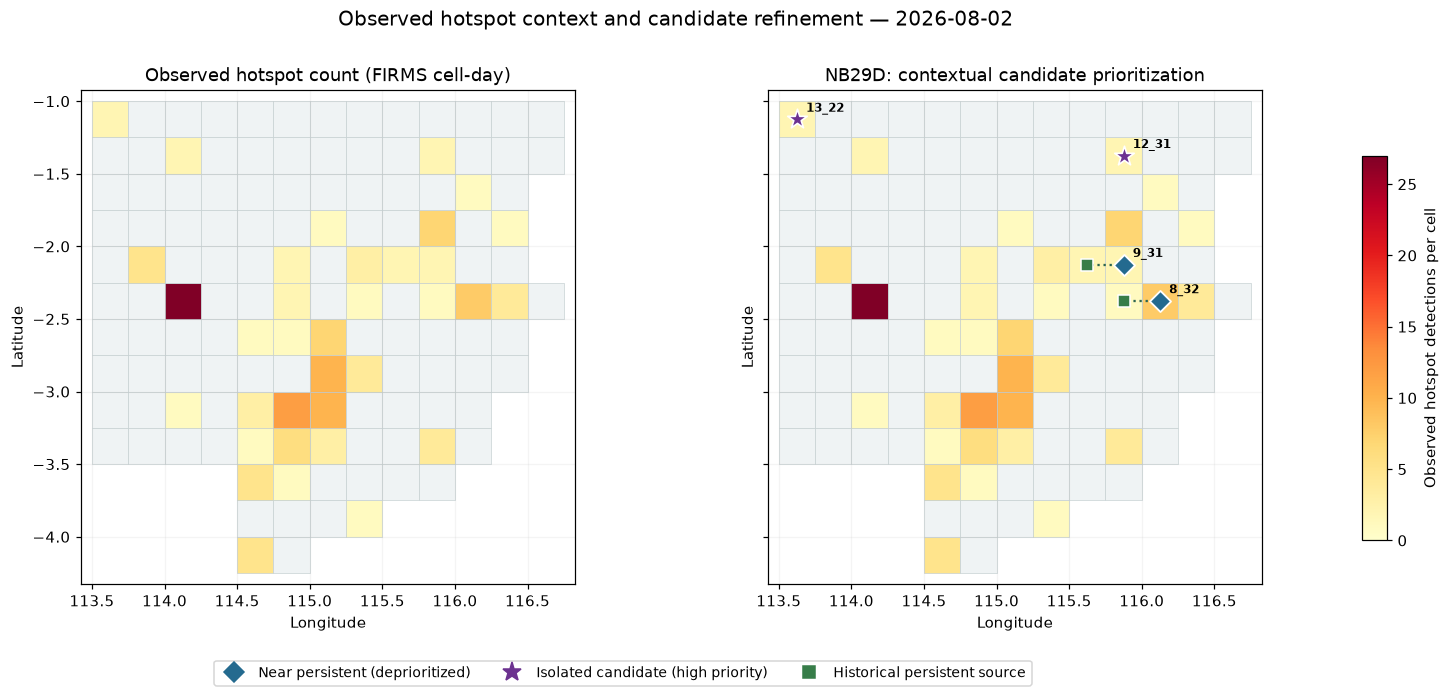

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2\figures\06_observed_grid_case_map_2026-08-02.png


In [15]:
# 14. Grid-consistent actual hotspot and refinement case map
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch
obs=regional[regional.date.eq(TARGET_DATE)].copy()
assert len(obs)==133, f'Expected 133 cells, found {len(obs)}'
fig,axes=plt.subplots(1,2,figsize=(16,6.6),sharex=True,sharey=True)
max_count=max(1,int(obs.fire_count.max()))
for i,ax in enumerate(axes):
    for r in obs.itertuples(index=False):
        v=float(r.fire_count)
        col=plt.cm.YlOrRd(Normalize(0,max_count)(v)) if v>0 else '#EFF3F4'
        rect=Rectangle((float(r.grid_lon)-.125,float(r.grid_lat)-.125),.25,.25,edgecolor='#C3CED0',linewidth=.42,facecolor=col)
        ax.add_patch(rect)
    ax.set_aspect('equal',adjustable='box');ax.set_xlabel('Longitude');ax.set_ylabel('Latitude')
    ax.set_xlim(obs.grid_lon.min()-.20,obs.grid_lon.max()+.20)
    ax.set_ylim(obs.grid_lat.min()-.20,obs.grid_lat.max()+.20)
    ax.grid(alpha=.13)
    ax.set_title('Observed hotspot count (FIRMS cell-day)' if i==0 else 'NB29D: contextual candidate prioritization')
    if i==1:
        for r in selected_near.itertuples(index=False):
            ax.scatter(r.grid_lon,r.grid_lat,marker='D',s=95,c='#246A8F',edgecolors='white',linewidths=1.2,zorder=10)
            if pd.notna(r.near_persistent_source_lat) and pd.notna(r.near_persistent_source_lon):
                ax.scatter(r.near_persistent_source_lon,r.near_persistent_source_lat,marker='s',s=70,c='#377D49',edgecolors='white',linewidths=1,zorder=12)
                ax.plot([r.grid_lon,r.near_persistent_source_lon],[r.grid_lat,r.near_persistent_source_lat],color='#2D6551',linestyle=':',lw=1.5,zorder=9)
        for r in selected_far.itertuples(index=False):
            ax.scatter(r.grid_lon,r.grid_lat,marker='*',s=180,c='#6C3290',edgecolors='white',linewidths=1.1,zorder=10)
        for r in selected_cases.itertuples(index=False):
            ax.annotate(str(r.cell_id).replace('regional025_',''),(r.grid_lon,r.grid_lat),xytext=(6,5),textcoords='offset points',fontsize=8,fontweight='bold')
fig.subplots_adjust(right=.87,top=.85,bottom=.17,wspace=.10)
cax=fig.add_axes([.89,.23,.014,.53])
sm=ScalarMappable(norm=Normalize(0,max_count),cmap='YlOrRd'); sm.set_array([])
fig.colorbar(sm,cax=cax,label='Observed hotspot detections per cell')
legend=[Line2D([0],[0],marker='D',markersize=9,linestyle='',color='#246A8F',label='Near persistent (deprioritized)'),
        Line2D([0],[0],marker='*',markersize=13,linestyle='',color='#6C3290',label='Isolated candidate (high priority)'),
        Line2D([0],[0],marker='s',markersize=8,linestyle='',color='#377D49',label='Historical persistent source')]
fig.legend(handles=legend,loc='lower center',ncol=3,bbox_to_anchor=(.47,.02),fontsize=9)
fig.suptitle(f'Observed hotspot context and candidate refinement — {TARGET_DATE.date()}',y=.96,fontsize=13)
p=FIG/f'06_observed_grid_case_map_{TARGET_DATE.date()}.png'
fig.savefig(p,dpi=230,bbox_inches='tight');plt.show();print('Saved:',p)

# PART VI — Vegetation feasibility and missing ground truth

Dynamic World NB23D2 tested multiple past-observation windows. Its reliability gate was defined **before inspecting vegetation-class differences**; no tested window passed for both pre-existing candidate groups. This is **not evidence that vegetation has no role**: it is a coverage/identifiability limitation. Static land cover such as ESA WorldCover could be attempted later, but 2021 classes cannot substantiate *actual vegetation condition in August 2026* or fire causes. NB33 does **not** silently substitute static land cover for dynamic vegetation.

In [16]:
# 15. Dynamic World feasibility gate (if source export available)
vegetation_status='Not assessed in NB33 because NB23D2 exported coverage decision was not found.'
if PATHS['dynamic_world_gate'].exists():
    dw=pd.read_csv(PATHS['dynamic_world_gate'])
    assert {'window_days','passes_both_groups'}.issubset(dw.columns)
    display(dw)
    passing=dw.loc[dw.passes_both_groups.astype(str).str.lower().eq('true'),'window_days'].tolist()
    if passing:
        vegetation_status=f'Dynamic World: eligible windows {passing}; revisit NB23D2 before using features.'
    else:
        vegetation_status='Dynamic World: none of tested 60/90/120/180-day windows passed the pre-set two-group reliable-coverage gate; do not use temporal vegetation comparison.'
else:
    print('NB23D2 coverage file missing; cannot verify vegetation-feasibility numbers from local exports.')
print(vegetation_status)

,window_days,coverage__History-novel / env-plausible,coverage__Robust joint-high,pass__History-novel / env-plausible,pass__Robust joint-high,passes_both_groups
0,60,0.283019,0.0,False,False,False
1,90,0.358491,0.0,False,False,False
2,120,0.566038,0.0,False,False,False
3,180,0.603774,0.0,False,False,False


Dynamic World: none of tested 60/90/120/180-day windows passed the pre-set two-group reliable-coverage gate; do not use temporal vegetation comparison.


# PART VII — Supervisor synthesis and exports

Use the report to show **what is supported and what remains unverified**, not to claim GeoMAE-ST-Wind wins when measured PR-AUC contradicts that. Critically, **22 isolated candidates are not verified ignitions**, and **96 nearby candidates are not proven false positives**.

In [17]:
# 16. Supervisor brief — automatically grounded in loaded exports
geo_st=float(aug_pivot.loc['GeoMAE-ST','Emerging-3 eligible'])
geo_t=float(aug_pivot.loc['GeoMAE-T','Emerging-3 eligible'])
geo_w=float(aug_pivot.loc['GeoMAE-ST-Wind','Emerging-3 eligible'])
nodegru=float(aug_pivot.loc['NodeGRU-L14 baseline','Emerging-3 eligible'])
lr=float(aug_pivot.loc['LR13 baseline','Emerging-3 eligible'])
scratch=float(aug_pivot.loc['Transformer-ST-Wind Scratch','Emerging-3 eligible'])

claim_status=(
    'GeoMAE-ST is above NodeGRU on August Emerging PR-AUC.' if geo_st>nodegru else
    'GeoMAE-ST does not exceed NodeGRU on August Emerging PR-AUC.'
)
report=f"""# Bimbingan — Research Synthesis (NB33)

## One-sentence objective
Combine **next-day FIRMS hotspot ranking** with **subsequent GeoMAE-inspired contextual hotspot anomaly identification**, and prioritize unusual observed cell-days based on recent spatial context and supportive wind evidence.

## Chronological research story
1. At end of day **t**, predict target-cell hotspot observation at **t+1** from known history (forecasting family based on NB24 pretraining; LR13/NodeGRU benchmarks).
2. When observed FIRMS detections from **t+1** arrive, assess unusual patterns using the **separately trained fire-only temporal masked-reconstruction** anomaly model (NB25).
3. For observed robust Emerging-3 anomaly candidates, compare to hotspot sources active **at least 2 of previous 3 days**; within **40 km** is **deprioritized / spatially explainable**, not a confirmed false positive (NB29D).
4. Add **wind support** only as contextual evidence, not proof of fire propagation or causality.

## Anomaly-refinement outcomes — August
- Robust hotspot candidates (all groups): {robust_total if robust_total is not None else 'not available in the loaded exports'}.
- Emerging-3 robust candidates: **{len(refined)}**.
- Near prior persistent source: **{int(near.sum())}**, including **{int((near & wind_supportive).sum())}** with supportive wind evidence.
- Isolated from prior persistent source at 40 km: **{int(isolated.sum())}** higher-priority investigation candidates.
- Sensitivity important: source persistence threshold and neighborhood radius affect the result; **do not report candidate counts as validated false-positive reduction.**

## Forecasting model comparison — August development, Emerging-3 PR-AUC
- LR13 baseline: **{lr:.4f}**.
- NodeGRU-L14 baseline: **{nodegru:.4f}**.
- GeoMAE-T: **{geo_t:.4f}**.
- GeoMAE-ST: **{geo_st:.4f}**.
- GeoMAE-ST-Wind: **{geo_w:.4f}**.
- Scratch ST-Wind: **{scratch:.4f}**.
- Spatial delta (ST − T): **{geo_st-geo_t:+.4f}**.
- Additional wind delta (ST-Wind − ST): **{geo_w-geo_st:+.4f}**.
- Pretraining delta (ST-Wind − scratch): **{geo_w-scratch:+.4f}**.
- **Interpretation:** {claim_status} Spatial appears helpful for this development dataset; explicit wind addition currently reduces Emerging PR-AUC. These are association/ablation results with design limitations, not universal physical or causal claims.

## Vegetation
{vegetation_status}

## What this research contributes
- A **two-stage, chronologically coherent** forecasting-plus-contextual-anomaly investigation workflow.
- A traceable, distance-first priority rule for unusual observed hotspot patterns.
- Transparent development evidence comparing pretrained, spatial, and wind-aware forecasting variants, including unfavorable results.

## Limitations that must be disclosed
- FIRMS hotspots are satellite thermal detections, **not verified wildfire ignitions**; proximity and wind alignment do not establish causation or flame spread.
- No independently labeled true anomaly / anthropogenic ignition / confirmed false-positive reference data.
- Spatial resolution **0.25°** is coarse, so 30–50 km distinctions require sensitivity analyses.
- **August was used for development**, and **September has been examined**. This notebook does not create an independent untouched test.
- Final temporal fire-only anomaly model and spatiotemporal forecasting model are **different trained encoders/checkpoints** despite sharing GeoMAE-inspired modeling ideas.

## Proposed next actions
1. Ask supervisor to agree on the formal research goal: forecasting plus retrospective contextual prioritization.
2. Validate suspicious candidates using an independent incident reference or more temporally aligned remote sensing if available.
3. Obtain a new time period or geographic region for independent confirmation before claiming generalization.
4. If vegetation is required, source contemporaneous vegetation/land-cover imagery, record missingness and matching uncertainty, and **avoid claiming 2021 static land cover is 2026 vegetation condition**.
"""
summary_path=OUT/'NB33_supervisor_brief.md'; summary_path.write_text(report,encoding='utf-8')
display(Markdown(report))
print('Saved:',summary_path)

# Bimbingan — Research Synthesis (NB33)

## One-sentence objective
Combine **next-day FIRMS hotspot ranking** with **subsequent GeoMAE-inspired contextual hotspot anomaly identification**, and prioritize unusual observed cell-days based on recent spatial context and supportive wind evidence.

## Chronological research story
1. At end of day **t**, predict target-cell hotspot observation at **t+1** from known history (forecasting family based on NB24 pretraining; LR13/NodeGRU benchmarks).
2. When observed FIRMS detections from **t+1** arrive, assess unusual patterns using the **separately trained fire-only temporal masked-reconstruction** anomaly model (NB25).
3. For observed robust Emerging-3 anomaly candidates, compare to hotspot sources active **at least 2 of previous 3 days**; within **40 km** is **deprioritized / spatially explainable**, not a confirmed false positive (NB29D).
4. Add **wind support** only as contextual evidence, not proof of fire propagation or causality.

## Anomaly-refinement outcomes — August
- Robust hotspot candidates (all groups): 620.
- Emerging-3 robust candidates: **118**.
- Near prior persistent source: **96**, including **55** with supportive wind evidence.
- Isolated from prior persistent source at 40 km: **22** higher-priority investigation candidates.
- Sensitivity important: source persistence threshold and neighborhood radius affect the result; **do not report candidate counts as validated false-positive reduction.**

## Forecasting model comparison — August development, Emerging-3 PR-AUC
- LR13 baseline: **0.2770**.
- NodeGRU-L14 baseline: **0.3372**.
- GeoMAE-T: **0.2886**.
- GeoMAE-ST: **0.3220**.
- GeoMAE-ST-Wind: **0.2855**.
- Scratch ST-Wind: **0.2529**.
- Spatial delta (ST − T): **+0.0335**.
- Additional wind delta (ST-Wind − ST): **-0.0365**.
- Pretraining delta (ST-Wind − scratch): **+0.0327**.
- **Interpretation:** GeoMAE-ST does not exceed NodeGRU on August Emerging PR-AUC. Spatial appears helpful for this development dataset; explicit wind addition currently reduces Emerging PR-AUC. These are association/ablation results with design limitations, not universal physical or causal claims.

## Vegetation
Dynamic World: none of tested 60/90/120/180-day windows passed the pre-set two-group reliable-coverage gate; do not use temporal vegetation comparison.

## What this research contributes
- A **two-stage, chronologically coherent** forecasting-plus-contextual-anomaly investigation workflow.
- A traceable, distance-first priority rule for unusual observed hotspot patterns.
- Transparent development evidence comparing pretrained, spatial, and wind-aware forecasting variants, including unfavorable results.

## Limitations that must be disclosed
- FIRMS hotspots are satellite thermal detections, **not verified wildfire ignitions**; proximity and wind alignment do not establish causation or flame spread.
- No independently labeled true anomaly / anthropogenic ignition / confirmed false-positive reference data.
- Spatial resolution **0.25°** is coarse, so 30–50 km distinctions require sensitivity analyses.
- **August was used for development**, and **September has been examined**. This notebook does not create an independent untouched test.
- Final temporal fire-only anomaly model and spatiotemporal forecasting model are **different trained encoders/checkpoints** despite sharing GeoMAE-inspired modeling ideas.

## Proposed next actions
1. Ask supervisor to agree on the formal research goal: forecasting plus retrospective contextual prioritization.
2. Validate suspicious candidates using an independent incident reference or more temporally aligned remote sensing if available.
3. Obtain a new time period or geographic region for independent confirmation before claiming generalization.
4. If vegetation is required, source contemporaneous vegetation/land-cover imagery, record missingness and matching uncertainty, and **avoid claiming 2021 static land cover is 2026 vegetation condition**.


Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2\NB33_supervisor_brief.md


In [18]:
# 17. Export reproducible tables + provenance manifest
for name,df_ in [
  ('nb33_anomaly_refinement_counts',anomaly_counts),
  ('nb33_anomaly_sensitivity_neutral_wind',ss),
  ('nb33_august_matched_forecasting_pr_auc',aug_results),
  ('nb33_august_component_deltas',difference),
  ('nb33_selected_day_anomaly_cases',selected_cases),
  ('nb33_input_provenance',input_audit),
]: df_.to_csv(EX/f'{name}.csv',index=False)
if len(sept_report):sept_report.to_csv(EX/'nb33_september_post_test_forecasting_pr_auc.csv',index=False)
manifest={
 'notebook':'33_research_synthesis_supervisor_report',
 'scope':'synthesis of existing executed exports; no fitting or threshold selection',
 'region':'T2 / 133 retained grid cells / 0.25 degree',
 'august_status':'development / post-development descriptive',
 'september_status':'NB21 original held-out, NB30/31 post-test exploratory',
 'anomaly_model':'NB25 fire-only temporal masked-reconstruction; distinct from ST forecast weights',
 'forecaster':'NB31B GeoMAE-inspired 7-day x 3x3 ST variants plus LR13/NodeGRU baselines',
 'persistent_source_rule':{'previous_days':3,'min_hotspot_positive_days':2,'near_radius_km':40},
 'input_files':{k:str(p) if p.exists() else None for k,p in PATHS.items()},
 'figures':[x.name for x in sorted(FIG.glob('*.png'))],
 'warning':'no confirmed false-positive, spread, ignition-cause, or calibrated probability claim'
}
(OUT/'NB33_methodology_and_provenance.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('=== NB33 COMPLETE ===')
print('Supervisor brief:',summary_path)
print('Figures:',len(list(FIG.glob('*.png'))),'| CSVs:',len(list(EX.glob('*.csv'))))
print('Output directory:',OUT)

=== NB33 COMPLETE ===
Supervisor brief: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2\NB33_supervisor_brief.md
Figures: 6 | CSVs: 7
Output directory: c:\Users\Asus\Documents\skripsi-karhut\model_results\research_synthesis_supervisor\t2


# Suggested 5-minute presentation sequence

1. **Problem and timeline:** predicted hotspot presence at t+1 is different from explaining a hotspot already observed at t+1.
2. **Forecast comparison:** LR13 and NodeGRU are strong baselines; GeoMAE-ST is competitive on Emerging but **not best**. Show August results and separately state September history.
3. **GeoMAE anomaly results:** 620 robust candidates in August overall; focus on 118 Emerging robust (the 620 figure is verifiable from NB25 export).
4. **Contextual refinement:** 96 within 40 km of persistent source, 22 isolated candidates; wind is supportive for 55 near-source cases. Demonstrate sensitivity 30/40/50 km and 2/3 vs 3/3 source persistence.
5. **Vegetation feasibility and next work:** Dynamic World coverage gate did not pass (if corresponding export is available); discuss independent validation and new held-out data.

**Do not say:** "GeoMAE-ST-Wind beats NodeGRU", "96 false positives eliminated", "wind proves spread", or "model predicts anthropogenic burning".